# Generador de Gráficos 2.1 a 2.4 (Estandarizado Villa Gaucho)

Este cuaderno es una versión estandarizada de `generador_graficos 2_1 - 2_4.ipynb`, aplicando las especificaciones de diseño y formato del Informe de Villa Gaucho:
- **Tipografía y tamaño de letra 14**: configurado globalmente para títulos, etiquetas de ejes, valores y señalizaciones.
- **Gráficos de Barras (Cuantitativas discretas: Días de las comidas en la semana)**:
  - **Regla del 2%**: Si el porcentaje de respuestas es **menor a 2%**, la frecuencia absoluta y el porcentaje aparecen **afuera de la barra** (`"X (Y,Y%)"`). Si es **>= 2%**, la frecuencia absoluta aparece **adentro de la barra** en blanco y negrita (tamaño 14).
  - Color único institucional: **`#1b7882`**.
  - Cuadrícula vertical punteada suave (`linestyle='--'`).


In [20]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN GLOBAL
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración global de tamaño de letra 14
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.titlesize'] = 14

# Color estándar para gráficos de barras de un solo color
COLOR_BARRAS_UNICO = '#1b7882'


In [21]:
# ==============================================================================
# 2. FUNCIÓN DE BARRAS HORIZONTALES ESTANDARIZADA
# ==============================================================================
def graficar_barras_horizontales(etiquetas, valores, titulo="", xlabel="Cantidad de respuestas", ylabel="Cantidad de días", sufijo_etiqueta="días", figsize=(12, 6)):
    """
    Genera un gráfico de barras horizontales estandarizado:
    - Si porcentaje < 2%, frecuencia y porcentaje van afuera de la barra.
    - Si porcentaje >= 2%, frecuencia adentro de la barra (blanco, negrita) y porcentaje afuera.
    - Color #1b7882.
    - Cuadrícula vertical punteada.
    """
    valores = np.array(valores, dtype=float)
    total = np.sum(valores)
    porcentajes = (valores / total) * 100 if total > 0 else np.zeros_like(valores)
    n = len(etiquetas)

    fig, ax = plt.subplots(figsize=figsize)

    barras = ax.barh(
        range(n),
        valores,
        color=COLOR_BARRAS_UNICO,
        height=0.68,
        edgecolor='none'
    )

    ax.set_yticks(range(n))
    if sufijo_etiqueta:
        labels_y = [f"{lbl} {sufijo_etiqueta}" if int(lbl) != 1 else f"{lbl} {sufijo_etiqueta.rstrip('s')}" for lbl in etiquetas]
    else:
        labels_y = [str(lbl) for lbl in etiquetas]
    ax.set_yticklabels(labels_y, fontsize=14)

    max_val = max(valores) if len(valores) > 0 else 1
    offset_porcentaje = max_val * 0.025

    for barra, cantidad, porcentaje in zip(barras, valores, porcentajes):
        x = barra.get_width()
        y = barra.get_y() + barra.get_height() / 2.0

        # REGLA DEL 2%:
        if porcentaje < 2.0:
            # Afuera de la barra si es menor al 2%
            ax.text(
                x + offset_porcentaje, y,
                f"{int(cantidad)} ({porcentaje:.1f}%)".replace('.', ','),
                ha='left', va='center',
                color='#202124', fontsize=14, fontweight='medium'
            )
        else:
            # Frecuencia adentro y porcentaje afuera
            ax.text(
                x / 2.0, y, str(int(cantidad)),
                ha='center', va='center',
                color='white', fontweight='bold', fontsize=14
            )
            ax.text(
                x + offset_porcentaje, y,
                f"{porcentaje:.1f}%".replace('.', ','),
                ha='left', va='center',
                color='#202124', fontsize=14
            )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=15, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    ax.set_xlim(0, max_val * 1.25)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


## 3. Carga y Procesamiento de Datos


In [22]:
# Cargar el archivo CSV con los datos del proyecto
df = pd.read_csv('datos.csv')

# Columnas de las 4 comidas: Desayuno (2.1), Almuerzo (2.2), Merienda (2.3), Cena (2.4)
cols_2_1 = [f'2.1 desayuna? [{i}] cant' for i in range(8)]
cols_2_2 = [f'2.2 almuerza? [{i}] cant' for i in range(8)]
cols_2_3 = [f'2.3 merienda? [{i}] cant' for i in range(8)]
cols_2_4 = [f'2.4 cena? [{i}] cant' for i in range(8)]

# Conversión numérica y suma por días (0 a 7 días)
df_2_1_count = df[cols_2_1].apply(pd.to_numeric, errors='coerce').sum(axis=0).reset_index(drop=True)
df_2_2_count = df[cols_2_2].apply(pd.to_numeric, errors='coerce').sum(axis=0).reset_index(drop=True)
df_2_3_count = df[cols_2_3].apply(pd.to_numeric, errors='coerce').sum(axis=0).reset_index(drop=True)
df_2_4_count = df[cols_2_4].apply(pd.to_numeric, errors='coerce').sum(axis=0).reset_index(drop=True)

dias_indices = list(range(8))


## 4. Pregunta 2.1: Días en los que se desayuna


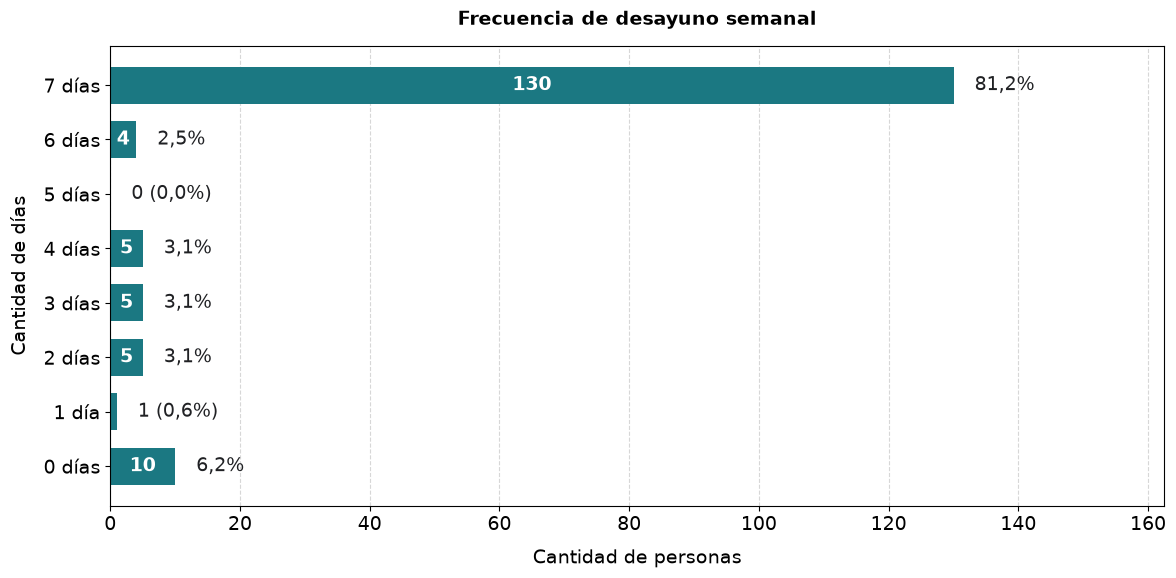

In [23]:
# Gráfico de barras: Días de desayuno en la semana (Variable Cuantitativa Discreta)
graficar_barras_horizontales(
    etiquetas=dias_indices,
    valores=df_2_1_count.values,
    titulo="Frecuencia de desayuno semanal",
    xlabel="Cantidad de personas",
    ylabel="Cantidad de días",
    sufijo_etiqueta="días"
)


## 5. Pregunta 2.2: Días en los que se almuerza


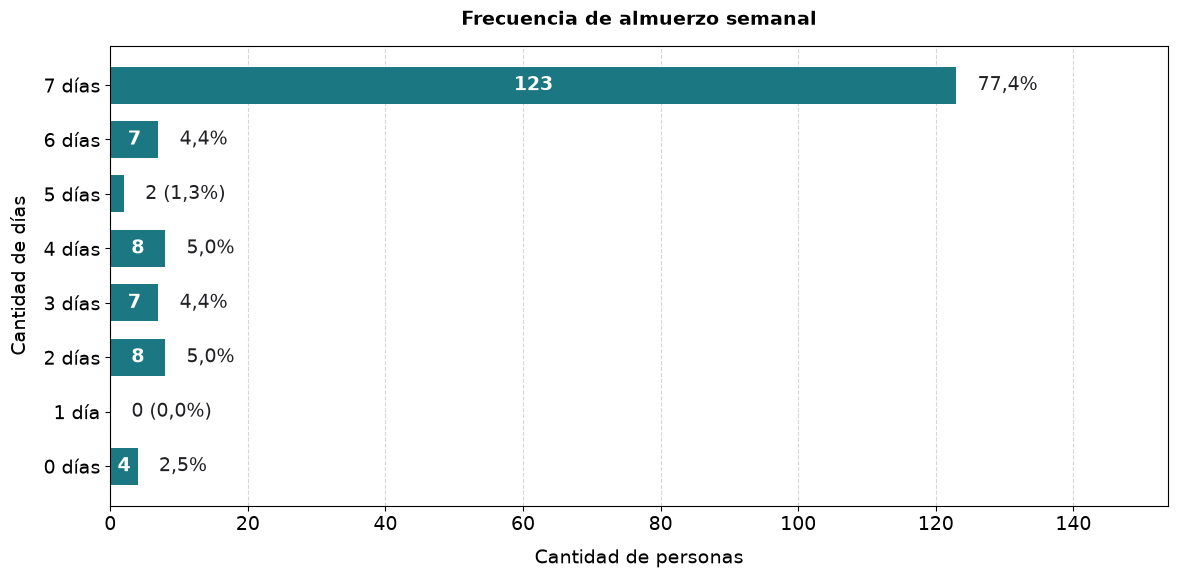

In [24]:
# Gráfico de barras: Días de almuerzo en la semana (Variable Cuantitativa Discreta)
graficar_barras_horizontales(
    etiquetas=dias_indices,
    valores=df_2_2_count.values,
    titulo="Frecuencia de almuerzo semanal",
    xlabel="Cantidad de personas",
    ylabel="Cantidad de días",
    sufijo_etiqueta="días"
)


## 6. Pregunta 2.3: Días en los que se merienda


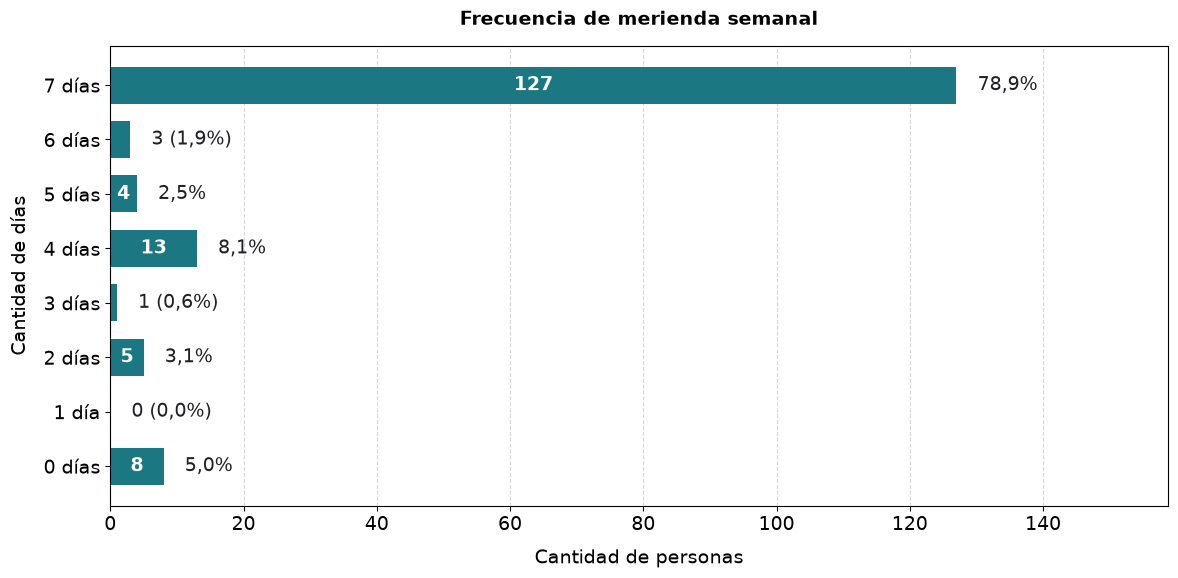

In [25]:
# Gráfico de barras: Días de merienda en la semana (Variable Cuantitativa Discreta)
graficar_barras_horizontales(
    etiquetas=dias_indices,
    valores=df_2_3_count.values,
    titulo="Frecuencia de merienda semanal",
    xlabel="Cantidad de personas",
    ylabel="Cantidad de días",
    sufijo_etiqueta="días"
)


## 7. Pregunta 2.4: Días en los que se cena


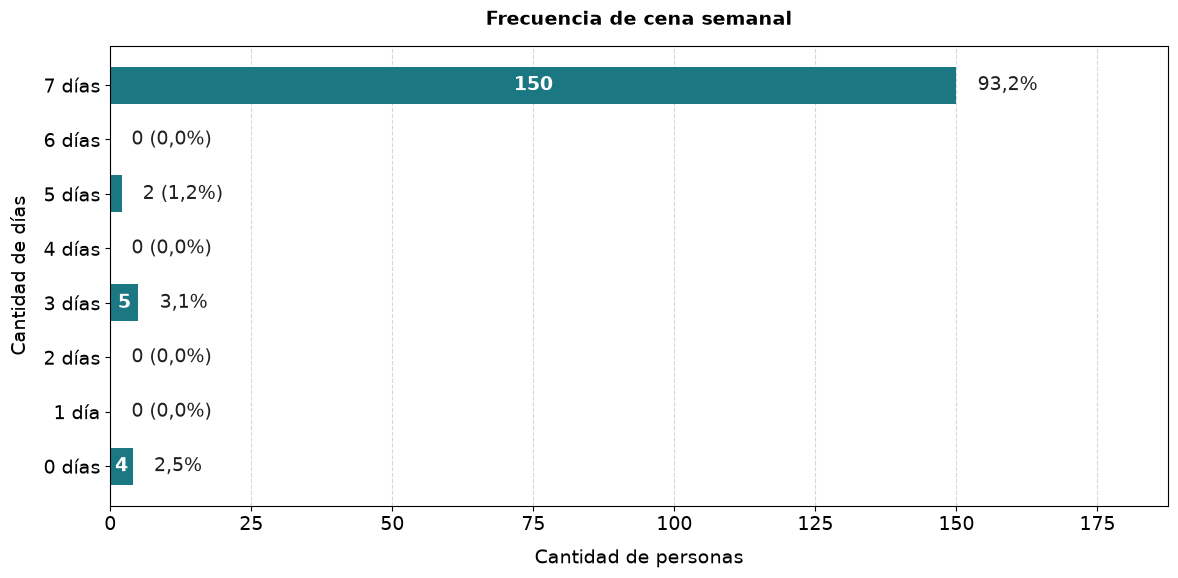

In [26]:
# Gráfico de barras: Días de cena en la semana (Variable Cuantitativa Discreta)
graficar_barras_horizontales(
    etiquetas=dias_indices,
    valores=df_2_4_count.values,
    titulo="Frecuencia de cena semanal",
    xlabel="Cantidad de personas",
    ylabel="Cantidad de días",
    sufijo_etiqueta="días"
)
